In [1]:
import math
import os
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from IPython.display import display

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)

# Walk up from the notebook folder to locate the repository's `code/` root
CODE_DIR = next(
    (c for p in (Path.cwd(), *Path.cwd().parents) for c in (p, p / "code") if all((c / d).is_dir() for d in ("kev", "data", "models"))),
    None,
)
if CODE_DIR is None:
    raise RuntimeError(f"No code/ root containing kev/, data/, and models/ at or above {Path.cwd()}")

# The `beta_ols` package (and this notebook's other modules) is in `src/` next to this notebook
EXPLORATION_DIR = CODE_DIR / "papers" / "beta-loss" / "exploration"
SRC_DIR = EXPLORATION_DIR / "src"
if not (SRC_DIR / "beta_ols").is_dir():
    raise RuntimeError(f"`beta_ols` package not found in {SRC_DIR}")

# Run from `code/` and expose `code/`, `code/kev/`, and `src/` on sys.path
os.chdir(CODE_DIR)
for _p in (str(CODE_DIR), str(CODE_DIR / "kev"), str(SRC_DIR)):
    if _p not in sys.path:
        sys.path.insert(0, _p)

from dataclasses import replace

from models.kev_pointer import KevPointerModel
from training import free_gpu

import beta_ols
from beta_ols import core as beta_core
from beta_train.config import TrainConfig, scale_lr_for_sample_size
from beta_train.diagnostics import find_max_micro_chunk, gradient_check
from beta_train.items import build_items_cached, items_summary
from beta_train.model_state import snapshot_trainable
from beta_train.reports import comparison_table, eval_beta_table, mse_decomposition, per_dataset_table
from beta_train.trainer import RunResult, run_training
from beta_train.validation import PopulationValidator, TrainingPathValidator, validate_all_cached, validation_metrics_frame

# Disk cache for training items and the untrained (step-0) validation; delete the folder to clear it
CACHE_DIR = CODE_DIR / ".cache" / "beta_training"

print(f"CODE_DIR: {CODE_DIR}")

CODE_DIR: /home/dw/github/decision-models-finetuning/code


In [2]:
# Require CUDA and release any previously loaded `kev_model` before allocating a fresh 800M backbone
if not torch.cuda.is_available():
    raise RuntimeError("CUDA GPU is required to run jaredpalmer/kev-0.8b in bf16 train mode")
if "kev_model" in globals():
    globals().pop("kev_model")
device = "cuda"
free_gpu()
torch.manual_seed(42)

# Model settings (also the key of the cached step-0 validation)
KEV_BASE = "jaredpalmer/kev-0.8b"
LORA_RANK = 64
WEIGHTS_DTYPE = "bf16"
HEAD_TEMPERATURE = 1.0   # training uses raw uncalibrated temperature = 1.0

# Build the frozen backbone + LoRA + pointer head
t_model0 = time.perf_counter()
kev_model = KevPointerModel.build(
    KEV_BASE,
    device=device,
    lora_rank=LORA_RANK,
    weights_dtype=WEIGHTS_DTYPE,
)
kev_model.net.head.temperature = HEAD_TEMPERATURE
kev_model.train()                     # enable training mode (LoRA dropout active, trainable params require_grad)
torch.cuda.synchronize()
model_load_sec = time.perf_counter() - t_model0

trainable_params_count = sum(p.numel() for p in kev_model.trainable_parameters())
total_params_count = sum(p.numel() for p in kev_model.parameters())
display(
    pd.Series(
        {
            "base_model": KEV_BASE,
            "mode": kev_model.mode,
            "training": kev_model.training,
            "weights_dtype": kev_model.meta.weights_dtype,
            "lora_rank": kev_model.meta.lora,
            "trainable_params": f"{trainable_params_count:,}",
            "total_params": f"{total_params_count:,}",
            "model_load_sec": round(model_load_sec, 3),
        },
        name="kev_800m_train_mode",
    ).to_frame()
)

# Snapshot the untrained trainable weights right after building, so every run, diagnostic, and the step-0
# validation start from them (rebuilding the model re-snapshots)
INIT_TRAINABLE_STATE = snapshot_trainable(kev_model)
MODEL_KEY = {"base": KEV_BASE, "lora_rank": LORA_RANK, "weights_dtype": WEIGHTS_DTYPE, "head_temperature": HEAD_TEMPERATURE}
print(f"Snapshotted {len(INIT_TRAINABLE_STATE)} trainable tensors")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

,kev_800m_train_mode
base_model,jaredpalmer/kev-0.8b
mode,lora_rank 64
training,True
weights_dtype,bf16
lora_rank,64
trainable_params,"43,815,424"
total_params,"796,208,448"
model_load_sec,1.597


Snapshotted 376 trainable tensors


# Datasets (loaded and replicated through `beta_ols`)

In [3]:
# Datasets this notebook uses; only these are loaded (the others are skipped to save time)
ITEM_DATASETS = [         # training items are built for these (training, gradient check, VRAM search)
    # "wu2025",
    "berke2023",
    # "kriner2026"

]
VALIDATION_DATASETS = [   # validation runs on these
    "grummon2025",
    "kriner2026",
]
LOADED_DATASETS = list(ITEM_DATASETS)
for dataset_name in VALIDATION_DATASETS:
    if dataset_name not in LOADED_DATASETS:
        LOADED_DATASETS.append(dataset_name)

# Load each through its `beta_ols` module: task rows, regression rows, regression specs, human OLS replication.
# Validation uses the whole dataset. Training splits a dataset with several task variables (`v`) into one pseudo
# dataset per task ("<dataset>/<v>"), so an item holds one respondent's tasks of a single kind.
choice_dfs: dict[str, pd.DataFrame] = {}
regression_rows_by_dataset: dict[str, pd.DataFrame] = {}
regression_specs_by_dataset: dict[str, dict] = {}
human_ols_by_dataset: dict[str, pd.DataFrame] = {}
module_by_dataset = {}    # (pseudo) dataset name -> the beta_ols module that codes its rows
TRAIN_DATASETS = []       # pseudo datasets of ITEM_DATASETS, the names training uses

for dataset_name in LOADED_DATASETS:
    dataset_module = beta_ols.DATASET_MODULES[dataset_name]
    full_choice_df = dataset_module.load_choice_df()
    pieces = {}
    if dataset_name in VALIDATION_DATASETS:
        pieces[dataset_name] = full_choice_df
    if dataset_name in ITEM_DATASETS:
        task_pieces = beta_core.split_by_task(full_choice_df, dataset_name)
        pieces.update(task_pieces)
        TRAIN_DATASETS.extend(task_pieces)

    for piece_name, choice_df in pieces.items():
        rows = dataset_module.regression_rows(choice_df)
        specs = dataset_module.regression_specs(rows)
        module_by_dataset[piece_name] = dataset_module
        choice_dfs[piece_name] = choice_df
        regression_rows_by_dataset[piece_name] = rows
        regression_specs_by_dataset[piece_name] = specs
        human_ols_by_dataset[piece_name] = beta_core.fit_human_ols(rows, specs)
        print(f"{piece_name}: {choice_df['CASEID'].nunique():,} respondents | {len(choice_df):,} tasks | {len(specs)} regression(s)")
        display(beta_core.wide_ols_table(human_ols_by_dataset[piece_name]).round(4))
print(f"TRAIN_DATASETS = {TRAIN_DATASETS}")


berke2023/delivery_choice_v0: 3,014 respondents | 9,528 tasks | 1 regression(s)


berke2023/v0                 
                                           beta      se std_beta
Drone privacy: YES vs NO                 0.1607  0.0095   0.3214
Fee L1 vs $0 ($1)                       -0.1509  0.0088  -0.3018
Fee L2 vs $0 ($3 fast / $5 meds)        -0.3298  0.0102  -0.6595
Fee L3 vs $0 ($5 fast / $10 meds)       -0.4978  0.0108  -0.9956
Wait L1 vs L0 (20m fast / 2h meds)      -0.0631  0.0107  -0.1261
Wait L2 vs L0 (30m fast / 6h meds)      -0.2082  0.0106  -0.4164
Wait L3 vs L0 (45m fast / 1d meds)      -0.3419  0.0124  -0.6837
sigma_y                                  0.5000     NaN      NaN
n_rows                               19056.0000     NaN      NaN

berke2023/delivery_choice_v1: 3,323 respondents | 11,481 tasks | 1 regression(s)


berke2023/v1                 
                                           beta      se std_beta
Drone privacy: YES vs NO                 0.2242  0.0088   0.4484
Fee L1 vs $0 ($1)                       -0.0822  0.0087  -0.1644
Fee L2 vs $0 ($3 fast / $5 meds)        -0.2964  0.0096  -0.5929
Fee L3 vs $0 ($5 fast / $10 meds)       -0.5023  0.0108  -1.0045
Wait L1 vs L0 (20m fast / 2h meds)      -0.0743  0.0095  -0.1487
Wait L2 vs L0 (30m fast / 6h meds)      -0.1924  0.0095  -0.3848
Wait L3 vs L0 (45m fast / 1d meds)      -0.2638  0.0102  -0.5276
sigma_y                                  0.5000     NaN      NaN
n_rows                               22962.0000     NaN      NaN

berke2023/delivery_choice_v2: 2,381 respondents | 7,269 tasks | 1 regression(s)


berke2023/v2                 
                                           beta      se std_beta
Drone privacy: YES vs NO                 0.2107  0.0111   0.4215
Fee L1 vs $0 ($1)                       -0.1534  0.0114  -0.3068
Fee L2 vs $0 ($3 fast / $5 meds)        -0.3251  0.0128  -0.6503
Fee L3 vs $0 ($5 fast / $10 meds)       -0.5268  0.0126  -1.0537
Wait L1 vs L0 (20m fast / 2h meds)      -0.0242  0.0109  -0.0484
Wait L2 vs L0 (30m fast / 6h meds)      -0.1521  0.0111  -0.3043
Wait L3 vs L0 (45m fast / 1d meds)      -0.2772  0.0130  -0.5545
sigma_y                                  0.5000     NaN      NaN
n_rows                               14538.0000     NaN      NaN

... (3 outputs left out)

grummon2025                 
                                          beta      se std_beta
NutritionInfo vs Positive               0.1844  0.0119   0.4196
HighIn vs Positive                      0.0541  0.0122   0.1231
Positive+NutritionInfo vs Positive      0.1788  0.0120   0.4069
Positive+HighIn vs Positive             0.1194  0.0122   0.2718
Spectrum vs Positive                    0.1083  0.0125   0.2464
sigma_y                                 0.4395     NaN      NaN
n_rows                              33798.0000     NaN      NaN

kriner2026: 1,000 respondents | 5,000 tasks | 1 regression(s)


kriner2026                 
                                       beta      se std_beta
Airline: Frontier                   -0.0854  0.0137  -0.1709
Airline: Southwest                  -0.0238  0.0139  -0.0476
Airline: United                     -0.0220  0.0132  -0.0440
Fuel: Sustainable aviation fuel      0.0691  0.0105   0.1381
Baggage: Checked bag+carry-on        0.0561  0.0124   0.1121
Baggage: Personal item only         -0.1393  0.0122  -0.2785
Space: Extra legroom                 0.0653  0.0097   0.1305
Seat: Middle                        -0.0906  0.0127  -0.1813
Seat: Window                         0.0384  0.0124   0.0769
Price: $275                         -0.0853  0.0137  -0.1705
Price: $300                         -0.1953  0.0142  -0.3907
Price: $325                         -0.3040  0.0143  -0.6080
sigma_y                              0.5000     NaN      NaN
n_rows                           10000.0000     NaN      NaN

TRAIN_DATASETS = ['berke2023/delivery_choice_v0', 'berke2023/delivery_choice_v1', 'berke2023/delivery_choice_v2', 'berke2023/delivery_choice_v3']


# Model, validators, and training items

In [4]:
# One validator per VALIDATION_DATASETS entry (population OLS from the dataset's module); pick how inference runs
VALIDATOR_KIND = "fused"   # "fused": LoRA merged + fused kernels + CUDA graphs, persona states shared
                           # "training_path": the training forward in eval mode, LoRA unmerged (no merge/offload/capture)
# "fused" per-GPU-batch inference budgets: lower them if validation runs out of memory (bigger models), raise for speed
VALIDATION_MAX_QUESTIONS = 1024
VALIDATION_MAX_CHARS = 1_000_000
# "training_path" items (data rows) per forward pass (no gradients, so far above the training micro-chunk)
VALIDATION_EVAL_CHUNK = 32

validators = {}
if VALIDATOR_KIND == "fused":
    for dataset_name in VALIDATION_DATASETS:
        validators[dataset_name] = PopulationValidator(
            beta_ols.DATASET_MODULES[dataset_name],
            choice_dfs[dataset_name],
            regression_specs_by_dataset[dataset_name],
            max_questions=VALIDATION_MAX_QUESTIONS,
            max_chars=VALIDATION_MAX_CHARS,
        )
elif VALIDATOR_KIND == "training_path":
    # The training path runs on items (tokenized respondents), cached on disk like the training items
    validation_modules = {}
    for dataset_name in VALIDATION_DATASETS:
        validation_modules[dataset_name] = beta_ols.DATASET_MODULES[dataset_name]
    validation_items, validation_items_report = build_items_cached(kev_model, validation_modules, choice_dfs, cache_dir=CACHE_DIR)
    display(validation_items_report)
    for dataset_name in VALIDATION_DATASETS:
        validators[dataset_name] = TrainingPathValidator(
            beta_ols.DATASET_MODULES[dataset_name],
            choice_dfs[dataset_name],
            regression_specs_by_dataset[dataset_name],
            validation_items[dataset_name],
            eval_chunk=VALIDATION_EVAL_CHUNK,
        )
else:
    raise ValueError(f"VALIDATOR_KIND must be 'fused' or 'training_path', got {VALIDATOR_KIND!r}")
display(pd.DataFrame([validator.describe() for validator in validators.values()]).set_index("validator"))

,kind,tasks,packed_persona_states,regressions,max_questions,max_chars,prep_sec
validator,,,,,,,
grummon2025,fused,33798,4906,grummon2025,1024,1000000,6.520
kriner2026,fused,5000,990,kriner2026,1024,1000000,0.809


In [5]:
# Untrained (step-0) validation, loaded from the disk cache when it already ran for this model, data, and code;
# reused as the first validation row of every run
step0_validation, step0_cache_report = validate_all_cached(
    kev_model,
    validators,
    INIT_TRAINABLE_STATE,
    model_key=MODEL_KEY,
    cache_dir=CACHE_DIR,
)
display(step0_cache_report)
display(validation_metrics_frame(step0_validation).round(4))
for dataset_name, (_, beta_df) in step0_validation.items():
    display(beta_df.round(4))

Evaluating grummon2025_validation (shared-state):   0%|          | 0/35 [00:00<?, ?batch/s]

Evaluating kriner2026_validation (shared-state):   0%|          | 0/5 [00:00<?, ?batch/s]

,source
validator,
grummon2025,computed
kriner2026,computed


,grummon2025,kriner2026
kl_loss,1.0589,1.0848
beta_mse,0.0055,0.0177
beta_mae,0.0651,0.1142
beta_mape_pct,64.7203,133.4387
spearman_rho,0.5000,-0.2657
eval_prep_sec,0.5015,0.0446
eval_gpu_sec,63.9160,8.0994
eval_wall_sec,66.5982,9.4398
eval_ms_per_task,1.9705,1.8880


,model,human_pop_beta,model_pop_beta,diff,abs_diff
term,,,,,
NutritionInfo vs Positive,grummon2025,0.1844,0.1280,-0.0564,0.0564
HighIn vs Positive,grummon2025,0.0541,0.1227,0.0686,0.0686
Positive+NutritionInfo vs Positive,grummon2025,0.1788,0.1573,-0.0216,0.0216
Positive+HighIn vs Positive,grummon2025,0.1194,-0.0085,-0.1279,0.1279
Spectrum vs Positive,grummon2025,0.1083,0.0573,-0.0510,0.0510


,model,human_pop_beta,model_pop_beta,diff,abs_diff
term,,,,,
Airline: Frontier,kriner2026,-0.0854,0.0343,0.1197,0.1197
Airline: Southwest,kriner2026,-0.0238,0.0266,0.0504,0.0504
Airline: United,kriner2026,-0.0220,0.0010,0.0229,0.0229
Fuel: Sustainable aviation fuel,kriner2026,0.0691,-0.0574,-0.1265,0.1265
Baggage: Checked bag+carry-on,kriner2026,0.0561,-0.0434,-0.0995,0.0995
Baggage: Personal item only,kriner2026,-0.1393,-0.0030,0.1363,0.1363
Space: Extra legroom,kriner2026,0.0653,-0.0813,-0.1466,0.1466
Seat: Middle,kriner2026,-0.0906,-0.0058,0.0849,0.0849
Seat: Window,kriner2026,0.0384,0.0085,-0.0299,0.0299


In [6]:
# Tokenize the TRAIN_DATASETS rows into training items (one per data row), loaded from the disk cache when they were already
# built for this data, tokenizer, and code; Kev's prepared targets are checked against each respondent's beta part

item_modules = {}
for dataset_name in TRAIN_DATASETS:
    item_modules[dataset_name] = module_by_dataset[dataset_name]
unified_items, items_cache_report = build_items_cached(kev_model, item_modules, choice_dfs, cache_dir=CACHE_DIR)
display(items_cache_report)
display(items_summary(unified_items, regression_specs_by_dataset))

,items (rows),source
dataset,,
berke2023/delivery_choice_v0,9528,cache
berke2023/delivery_choice_v1,11481,cache
berke2023/delivery_choice_v2,7269,cache
berke2023/delivery_choice_v3,8019,cache


,items (rows),respondents,regression_groups
dataset,,,
berke2023/delivery_choice_v0,9528,3014,berke2023/v0
berke2023/delivery_choice_v1,11481,3323,berke2023/v1
berke2023/delivery_choice_v2,7269,2381,berke2023/v2
berke2023/delivery_choice_v3,8019,2577,berke2023/v3


# Find max micro chunk

In [7]:
# Largest micro-chunk (items = data rows per chunk) that fits in VRAM for the worst-case (most padded) chunks of these datasets
SEARCH_GRADIENT_CHECKPOINTING = False   # search with the setting you will train with
SEARCH_MAX_CHUNK = 64
SEARCH_CANDIDATES_PER_SIZE = 3          # worst-case chunks tested per size; a size fits only if all of them fit

search_items = []
for dataset_name in TRAIN_DATASETS:
    search_items.extend(unified_items[dataset_name])
micro_chunk_search_df, MAX_FITTING_MICRO_CHUNK = find_max_micro_chunk(
    kev_model,
    search_items,
    INIT_TRAINABLE_STATE,
    max_chunk=SEARCH_MAX_CHUNK,
    gradient_checkpointing=SEARCH_GRADIENT_CHECKPOINTING,
    candidates_per_size=SEARCH_CANDIDATES_PER_SIZE,
)
display(micro_chunk_search_df)
print(f"gradient_checkpointing={SEARCH_GRADIENT_CHECKPOINTING} | MAX_FITTING_MICRO_CHUNK = {MAX_FITTING_MICRO_CHUNK}")

[W1116 01:29:48.671244164 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 58720256 bytes (free: 158400512, total: 33710276608).
[W1116 01:29:48.671330515 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 58720256 bytes (free: 158400512, total: 33710276608).
[W1116 01:29:51.765310517 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 77594624 bytes (free: 158859264, total: 33710276608).
[W1116 01:29:51.765408808 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 77594624 bytes (free: 158859264, total: 33710276608).
[W1116 01:29:54.837149165 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 73400320 bytes (free: 170000384, total: 33710276608).
[W1116 01:29:54.837239265 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM

,chunk_size,dataset,rule,padded_tokens,fits,peak_gib,peak_pct_of_vram
0,1,berke2023/delivery_choice_v3,longest state + longest branch + most questions,510,True,3.12,9.9
1,1,berke2023/delivery_choice_v3,longest branch + most questions,502,True,3.11,9.9
2,1,berke2023/delivery_choice_v2,longest state + longest branch + most questions,483,True,3.07,9.8
3,2,berke2023/delivery_choice_v3,longest state + longest branch + most questions,1020,True,4.53,14.4
4,2,berke2023/delivery_choice_v3,most padded tokens each,1020,True,4.53,14.4
5,2,berke2023/delivery_choice_v3,longest branch + most questions,1004,True,4.45,14.2
6,4,berke2023/delivery_choice_v3,longest state + longest branch + most questions,2040,True,7.28,23.2
7,4,berke2023/delivery_choice_v3,most padded tokens each,2040,True,7.28,23.2
8,4,berke2023/delivery_choice_v3,longest branch + most questions,2008,True,7.12,22.7
9,8,berke2023/delivery_choice_v3,longest state + longest branch + most questions,4080,True,12.73,40.6


gradient_checkpointing=False | MAX_FITTING_MICRO_CHUNK = 19


# Train

In [7]:
MAX_FITTING_MICRO_CHUNK = 18
SEARCH_GRADIENT_CHECKPOINTING = False

In [8]:
# Base run settings; each run cell below changes only beta_lambda
# BASE_LR_SAMPLE_1 = 2e-5   # validated 1-respondent/step LR; scaled by sqrt(sample size)
SAMPLE_SIZE = 64
# LR = scale_lr_for_sample_size(BASE_LR_SAMPLE_1, SAMPLE_SIZE)
LR = 5e-5
BASE_CONFIG = TrainConfig(
    # train_datasets=("grummon2023",),
    train_datasets=tuple(TRAIN_DATASETS),
    # sample_size_by_dataset={"grummon2023": SAMPLE_SIZE},
    sample_size_by_dataset={ts: SAMPLE_SIZE for ts in TRAIN_DATASETS},
    beta_lambda=0.0,
    lr=LR,
    num_epochs=5,
    eval_every=31,
    # eval_every=4,
    lr_schedule="onecycle",
    weight_decay=0.01,
    micro_chunk=MAX_FITTING_MICRO_CHUNK,
    gradient_checkpointing=SEARCH_GRADIENT_CHECKPOINTING,
    grad_clip=1.0,
    seed=42,
)
# Show a per-step bar over the micro-chunk passes (pass 1 forward, pass 2 forward + backward)
SHOW_CHUNK_PROGRESS = True
runs: dict[str, RunResult] = {}
display(pd.Series(BASE_CONFIG.as_dict(), name="base_config").to_frame())

,base_config
train_datasets,"[berke2023/delivery_choice_v0, berke2023/deliv..."
sample_size_by_dataset,"{'berke2023/delivery_choice_v0': 64, 'berke202..."
beta_lambda,0.0
lr,0.00005
num_epochs,5
eval_every,31
lr_schedule,onecycle
weight_decay,0.01
micro_chunk,18
gradient_checkpointing,False


,epoch,rows_seen,train_loss,grummon2025/kl_loss,grummon2025/beta_mse,grummon2025/beta_mae,grummon2025/beta_mape_pct,grummon2025/spearman_rho,kriner2026/kl_loss,kriner2026/beta_mse,kriner2026/beta_mae,kriner2026/beta_mape_pct,kriner2026/spearman_rho,lr,grummon2025/eval_wall_sec,kriner2026/eval_wall_sec,train_elapsed_sec
step,,,,,,,,,,,,,,,,,
0,0,0,NaN,1.05890,0.00546,0.06510,64.72026,0.5,1.08483,0.01775,0.11425,133.43868,-0.26573,NaN,66.59824,9.43978,0.00000
31,1,1984,0.66561,1.05013,0.00572,0.06861,60.57059,0.5,0.96779,0.01689,0.11113,129.07231,-0.25175,0.00000,64.92135,10.62803,58.65296
62,1,3941,0.57396,1.04057,0.00533,0.06531,57.95992,0.5,0.90836,0.01505,0.10663,127.49403,-0.14685,0.00001,63.55605,10.63410,113.10547
93,1,5925,0.54300,0.99446,0.00504,0.06829,62.47024,0.5,0.80940,0.01258,0.09847,118.06270,0.06294,0.00001,63.46476,10.60662,168.37630
124,1,7909,0.55280,0.95017,0.00373,0.05699,53.46048,0.5,0.73102,0.01049,0.09110,111.90331,0.12587,0.00002,63.35728,10.59253,223.15713
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2728,5,173997,0.49280,0.92580,0.00900,0.09031,71.84158,0.8,0.68443,0.00827,0.07670,86.59835,0.41259,0.00000,63.60075,10.83571,4830.42240
2759,5,175981,0.49297,0.92597,0.00902,0.09042,71.94119,0.8,0.68430,0.00827,0.07668,86.54834,0.41259,0.00000,63.58786,10.84488,4885.39013
2790,5,177965,0.47952,0.92575,0.00899,0.09030,71.85746,0.8,0.68438,0.00826,0.07663,86.51271,0.41259,0.00000,63.65222,10.80309,4940.11545


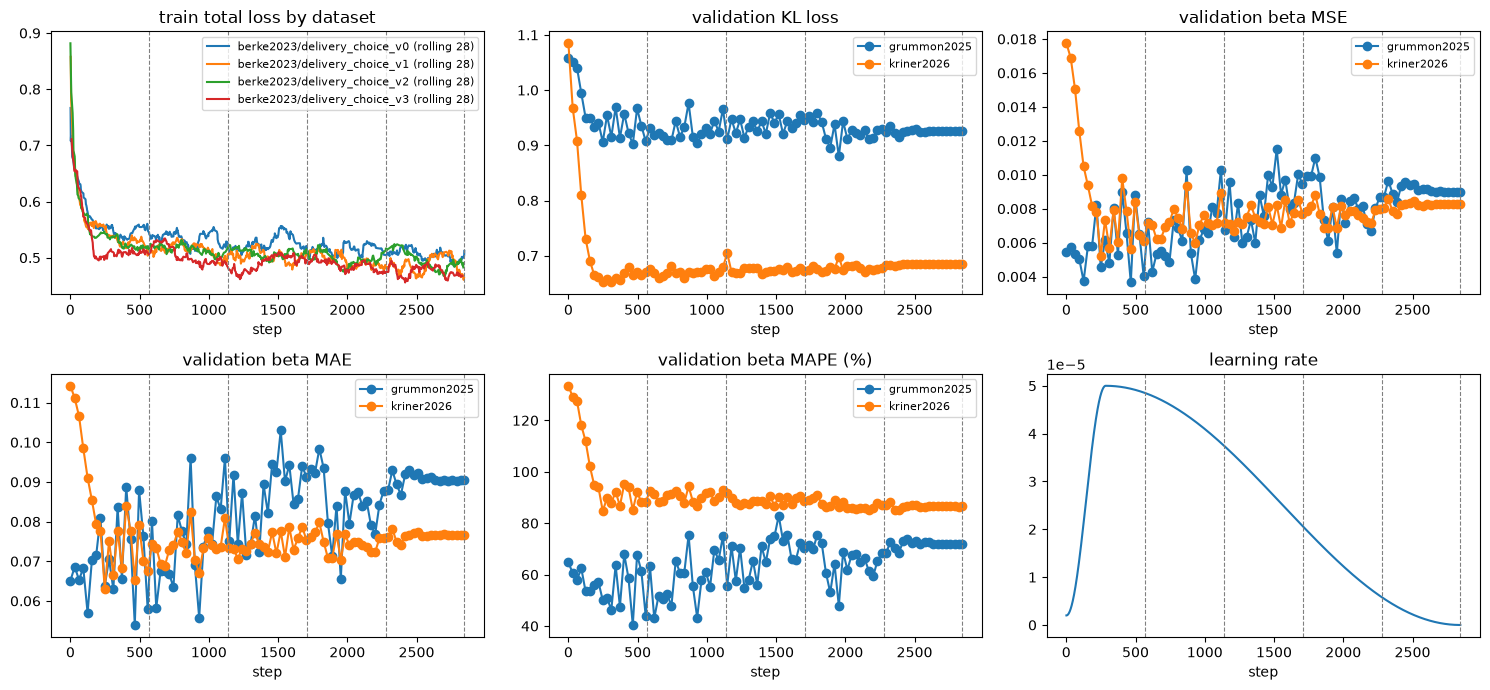

berke2023/delivery_choice_v0+berke2023/delivery_choice_v1+berke2023/delivery_choice_v2+berke2023/delivery_choi…

pass 1 (forward):   0%|          | 0/8 [00:00<?, ?it/s]

pass 1 (forward):   0%|          | 0/8 [00:00<?, ?it/s]

pass 1 (forward):   0%|          | 0/8 [00:00<?, ?it/s]

pass 1 (forward):   0%|          | 0/8 [00:00<?, ?it/s]

pass 1 (forward):   0%|          | 0/8 [00:00<?, ?it/s]

... (3,020 outputs left out)

pass 1 (forward):   0%|          | 0/8 [00:00<?, ?it/s]

pass 1 (forward):   0%|          | 0/8 [00:00<?, ?it/s]

Evaluating grummon2025_validation (shared-state):   0%|          | 0/35 [00:00<?, ?batch/s]

Evaluating kriner2026_validation (shared-state):   0%|          | 0/5 [00:00<?, ?batch/s]

In [9]:
# Run BASE_CONFIG with beta_lambda = 0
beta_lambda = 0.0
run_config = replace(BASE_CONFIG, beta_lambda=beta_lambda)
runs[f"lambda={run_config.beta_lambda:g}"] = run_training(
    model=kev_model,
    items_by_dataset=unified_items,
    specs_by_dataset=regression_specs_by_dataset,
    validators=validators,
    step0_validation=step0_validation,
    init_snapshot=INIT_TRAINABLE_STATE,
    config=run_config,
    device=device,
    show_chunk_progress=SHOW_CHUNK_PROGRESS,
)

,epoch,rows_seen,train_loss,grummon2025/kl_loss,grummon2025/beta_mse,grummon2025/beta_mae,grummon2025/beta_mape_pct,grummon2025/spearman_rho,kriner2026/kl_loss,kriner2026/beta_mse,kriner2026/beta_mae,kriner2026/beta_mape_pct,kriner2026/spearman_rho,lr,grummon2025/eval_wall_sec,kriner2026/eval_wall_sec,train_elapsed_sec
step,,,,,,,,,,,,,,,,,
0,0,0,NaN,1.05890,0.00546,0.06510,64.72026,0.5,1.08483,0.01775,0.11425,133.43868,-0.26573,NaN,66.59824,9.43978,0.00000
31,1,1984,0.72531,1.07137,0.00588,0.06807,60.03463,0.5,0.99417,0.01673,0.11119,130.57848,-0.24476,0.00000,63.69226,10.82371,54.83961
62,1,3941,0.59344,1.04755,0.00590,0.06940,60.22643,0.5,0.91194,0.01522,0.10714,127.88124,-0.20979,0.00001,63.65996,10.81771,109.11212
93,1,5925,0.56337,1.00119,0.00548,0.07109,64.35714,0.5,0.81125,0.01327,0.10049,119.19996,0.05594,0.00001,63.73258,10.87850,164.17467
124,1,7909,0.57823,0.95405,0.00338,0.05288,52.06169,0.5,0.72351,0.01028,0.09033,111.28674,0.11888,0.00002,63.64125,10.82841,218.95750
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2728,5,173997,0.50883,0.91599,0.00758,0.08553,77.14198,0.9,0.69466,0.00744,0.07396,89.97632,0.37762,0.00000,63.99294,11.16847,4827.28683
2759,5,175981,0.50910,0.91625,0.00761,0.08572,77.29354,0.9,0.69436,0.00743,0.07390,89.88982,0.37762,0.00000,63.99647,11.11352,4882.25695
2790,5,177965,0.49093,0.91577,0.00757,0.08547,77.10210,0.9,0.69447,0.00741,0.07381,89.78476,0.37762,0.00000,63.94223,11.19951,4936.97037


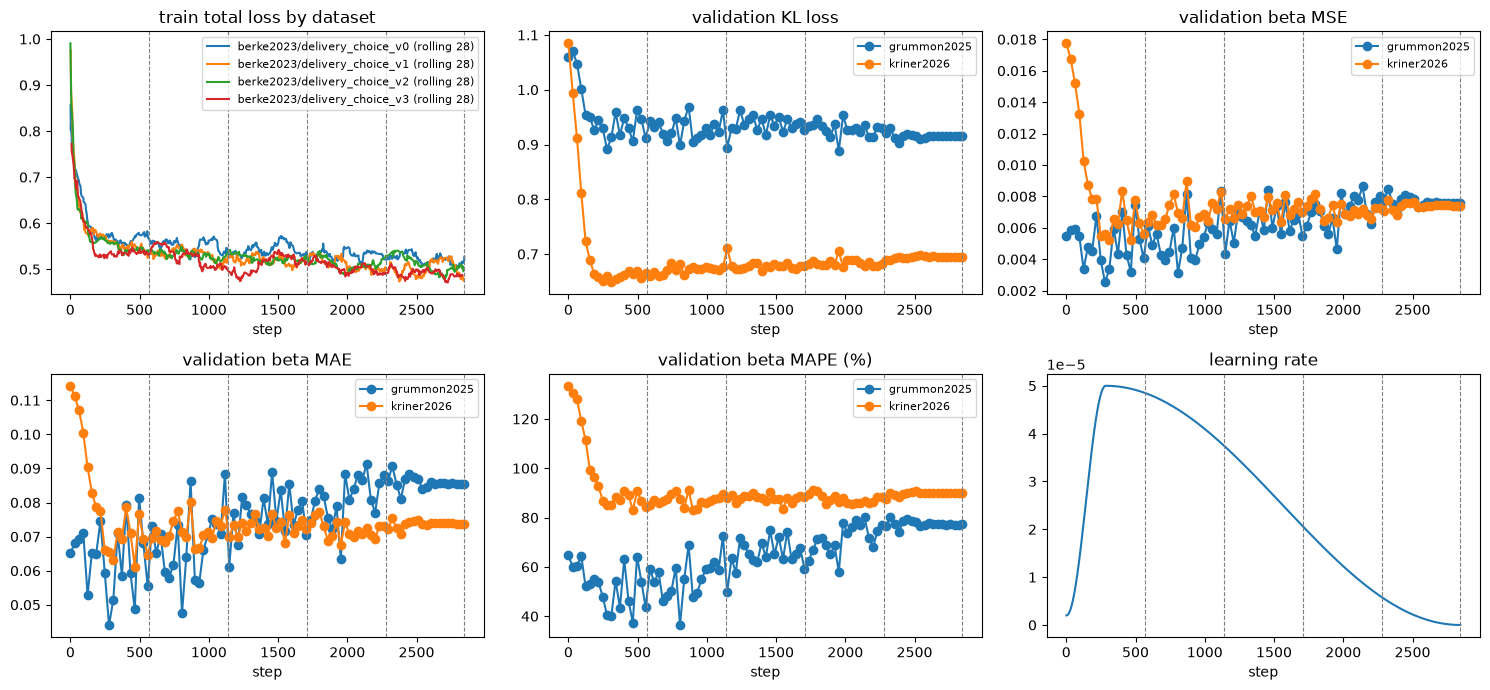

berke2023/delivery_choice_v0+berke2023/delivery_choice_v1+berke2023/delivery_choice_v2+berke2023/delivery_choi…

pass 1 (forward):   0%|          | 0/8 [00:00<?, ?it/s]

pass 1 (forward):   0%|          | 0/8 [00:00<?, ?it/s]

pass 1 (forward):   0%|          | 0/8 [00:00<?, ?it/s]

pass 1 (forward):   0%|          | 0/8 [00:00<?, ?it/s]

pass 1 (forward):   0%|          | 0/8 [00:00<?, ?it/s]

... (3,020 outputs left out)

pass 1 (forward):   0%|          | 0/8 [00:00<?, ?it/s]

pass 1 (forward):   0%|          | 0/8 [00:00<?, ?it/s]

Evaluating grummon2025_validation (shared-state):   0%|          | 0/35 [00:00<?, ?batch/s]

Evaluating kriner2026_validation (shared-state):   0%|          | 0/5 [00:00<?, ?batch/s]

In [10]:
beta_lambda = 0.25
run_config = replace(BASE_CONFIG, beta_lambda=beta_lambda)
runs[f"lambda={run_config.beta_lambda:g}"] = run_training(
    model=kev_model,
    items_by_dataset=unified_items,
    specs_by_dataset=regression_specs_by_dataset,
    validators=validators,
    step0_validation=step0_validation,
    init_snapshot=INIT_TRAINABLE_STATE,
    config=run_config,
    device=device,
    show_chunk_progress=SHOW_CHUNK_PROGRESS,
)

,epoch,rows_seen,train_loss,grummon2025/kl_loss,grummon2025/beta_mse,grummon2025/beta_mae,grummon2025/beta_mape_pct,grummon2025/spearman_rho,kriner2026/kl_loss,kriner2026/beta_mse,kriner2026/beta_mae,kriner2026/beta_mape_pct,kriner2026/spearman_rho,lr,grummon2025/eval_wall_sec,kriner2026/eval_wall_sec,train_elapsed_sec
step,,,,,,,,,,,,,,,,,
0,0,0,NaN,1.05890,0.00546,0.06510,64.72026,0.5,1.08483,0.01775,0.11425,133.43868,-0.26573,NaN,66.59824,9.43978,0.00000
31,1,1984,0.88274,1.11068,0.00618,0.06799,59.71836,0.5,1.04516,0.01668,0.11171,133.09121,-0.24476,0.00000,63.97269,11.28195,54.77160
62,1,3941,0.64655,1.07255,0.00663,0.07354,62.98647,0.5,0.95353,0.01511,0.10720,128.92854,-0.13287,0.00001,64.03342,11.17717,109.06472
93,1,5925,0.63287,1.01216,0.00658,0.07904,69.98661,-0.2,0.82980,0.01304,0.09973,118.19672,0.06294,0.00001,64.03635,11.19905,164.14690
124,1,7909,0.65225,0.94156,0.00366,0.05503,51.54688,0.5,0.73142,0.01009,0.08973,110.99854,0.11888,0.00002,65.93793,11.45949,222.67144
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2728,5,173997,0.56734,0.91317,0.00398,0.05536,41.63634,0.6,0.68127,0.00726,0.07404,91.53610,0.42657,0.00000,64.35137,11.48957,5166.80846
2759,5,175981,0.56357,0.91303,0.00397,0.05533,41.63695,0.6,0.68118,0.00726,0.07403,91.49290,0.42657,0.00000,64.35200,11.49321,5221.78610
2790,5,177965,0.53987,0.91284,0.00398,0.05540,41.69238,0.6,0.68129,0.00725,0.07397,91.43011,0.42657,0.00000,64.39283,11.44007,5276.50924


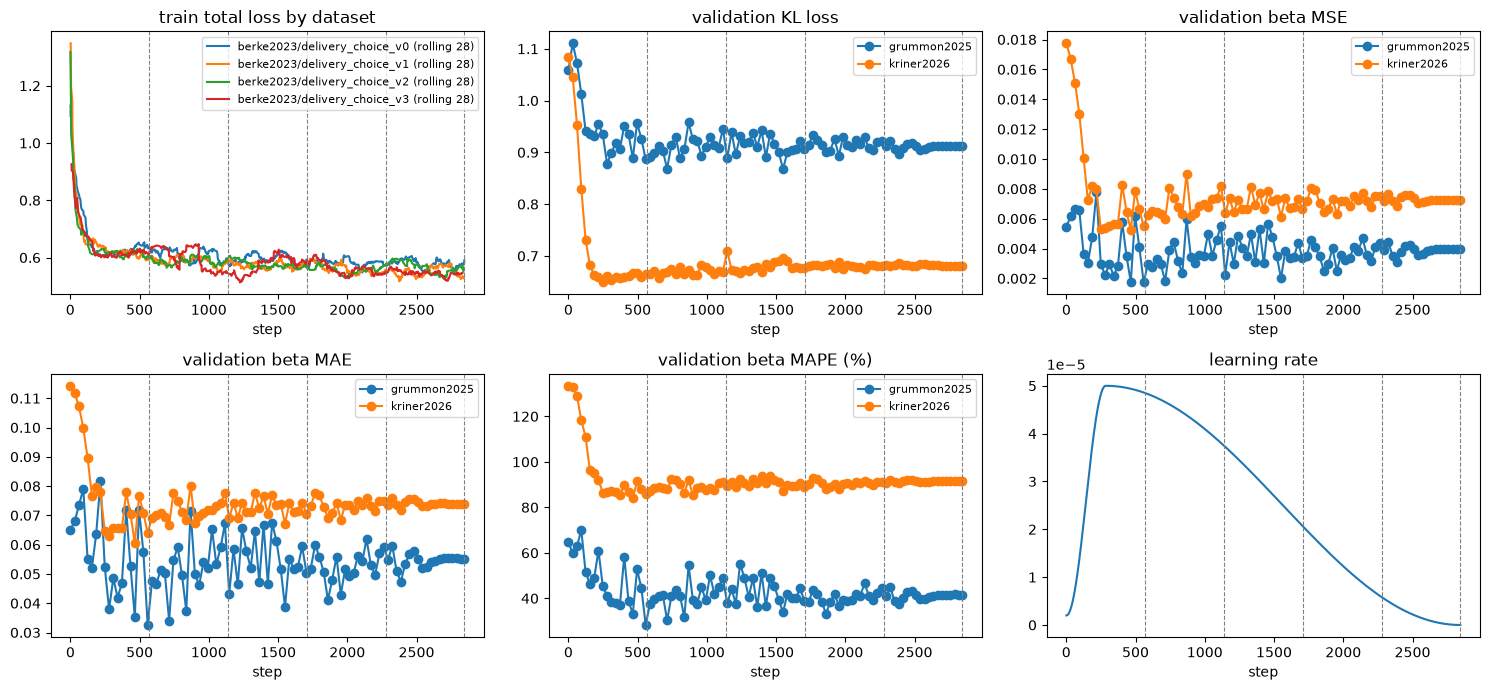

berke2023/delivery_choice_v0+berke2023/delivery_choice_v1+berke2023/delivery_choice_v2+berke2023/delivery_choi…

pass 1 (forward):   0%|          | 0/8 [00:00<?, ?it/s]

pass 1 (forward):   0%|          | 0/8 [00:00<?, ?it/s]

pass 1 (forward):   0%|          | 0/8 [00:00<?, ?it/s]

pass 1 (forward):   0%|          | 0/8 [00:00<?, ?it/s]

pass 1 (forward):   0%|          | 0/8 [00:00<?, ?it/s]

... (3,020 outputs left out)

pass 1 (forward):   0%|          | 0/8 [00:00<?, ?it/s]

pass 1 (forward):   0%|          | 0/8 [00:00<?, ?it/s]

Evaluating grummon2025_validation (shared-state):   0%|          | 0/35 [00:00<?, ?batch/s]

Evaluating kriner2026_validation (shared-state):   0%|          | 0/5 [00:00<?, ?batch/s]

In [11]:
beta_lambda = 1.00
run_config = replace(BASE_CONFIG, beta_lambda=beta_lambda)
runs[f"lambda={run_config.beta_lambda:g}"] = run_training(
    model=kev_model,
    items_by_dataset=unified_items,
    specs_by_dataset=regression_specs_by_dataset,
    validators=validators,
    step0_validation=step0_validation,
    init_snapshot=INIT_TRAINABLE_STATE,
    config=run_config,
    device=device,
    show_chunk_progress=SHOW_CHUNK_PROGRESS,
)

,epoch,rows_seen,train_loss,grummon2025/kl_loss,grummon2025/beta_mse,grummon2025/beta_mae,grummon2025/beta_mape_pct,grummon2025/spearman_rho,kriner2026/kl_loss,kriner2026/beta_mse,kriner2026/beta_mae,kriner2026/beta_mape_pct,kriner2026/spearman_rho,lr,grummon2025/eval_wall_sec,kriner2026/eval_wall_sec,train_elapsed_sec
step,,,,,,,,,,,,,,,,,
0,0,0,NaN,1.05890,0.00546,0.06510,64.72026,0.5,1.08483,0.01775,0.11425,133.43868,-0.26573,NaN,66.59824,9.43978,0.00000
31,1,1984,1.49743,1.14540,0.00675,0.06986,59.59407,0.5,1.09107,0.01659,0.11169,133.79428,-0.24476,0.00000,64.43691,11.59196,54.79313
62,1,3941,0.94235,1.10636,0.00704,0.07461,61.32242,0.5,0.96938,0.01512,0.10743,129.82898,-0.13287,0.00001,64.41293,11.99556,109.08597
93,1,5925,0.88976,1.05194,0.00629,0.07557,66.42449,0.5,0.88123,0.01401,0.10364,124.90648,-0.14685,0.00001,66.24853,11.83146,167.31237
124,1,7909,0.94815,0.98477,0.00393,0.05763,48.70111,0.5,0.77550,0.01070,0.09176,112.38810,0.16783,0.00002,64.40895,12.10555,224.37533
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2728,5,173997,0.79287,0.89583,0.00372,0.05166,46.93462,0.8,0.68956,0.00779,0.07612,94.75862,0.41958,0.00000,79.02339,13.29404,5326.82420
2759,5,175981,0.77301,0.89591,0.00372,0.05169,46.96575,0.8,0.68947,0.00779,0.07612,94.70129,0.41958,0.00000,79.36659,13.50201,5388.91101
2790,5,177965,0.71683,0.89586,0.00372,0.05160,46.91435,0.6,0.68963,0.00779,0.07611,94.74097,0.41958,0.00000,74.84507,14.97544,5460.95055


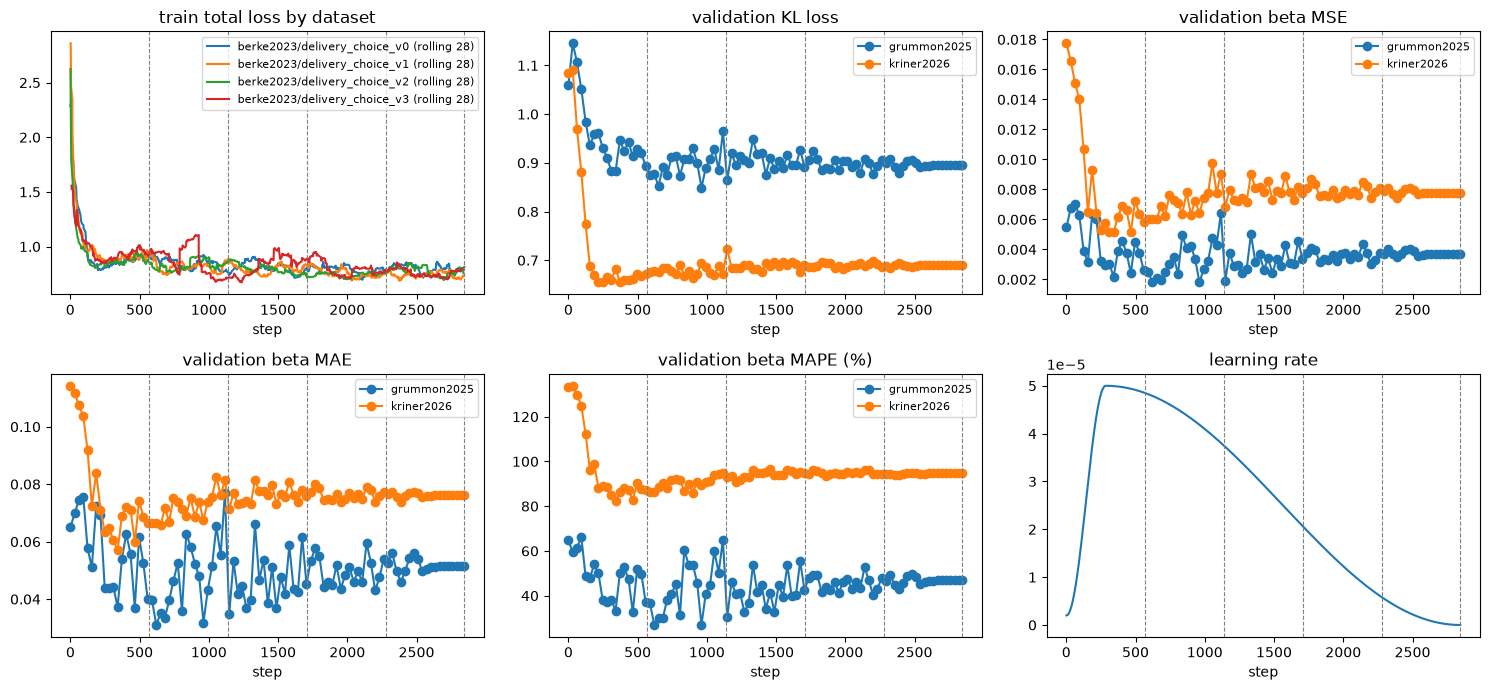

berke2023/delivery_choice_v0+berke2023/delivery_choice_v1+berke2023/delivery_choice_v2+berke2023/delivery_choi…

pass 1 (forward):   0%|          | 0/8 [00:00<?, ?it/s]

pass 1 (forward):   0%|          | 0/8 [00:00<?, ?it/s]

pass 1 (forward):   0%|          | 0/8 [00:00<?, ?it/s]

pass 1 (forward):   0%|          | 0/8 [00:00<?, ?it/s]

pass 1 (forward):   0%|          | 0/8 [00:00<?, ?it/s]

... (3,020 outputs left out)

pass 1 (forward):   0%|          | 0/8 [00:00<?, ?it/s]

pass 1 (forward):   0%|          | 0/8 [00:00<?, ?it/s]

Evaluating grummon2025_validation (shared-state):   0%|          | 0/35 [00:00<?, ?batch/s]

Evaluating kriner2026_validation (shared-state):   0%|          | 0/5 [00:00<?, ?batch/s]

In [12]:
beta_lambda = 4.0
run_config = replace(BASE_CONFIG, beta_lambda=beta_lambda)
runs[f"lambda={run_config.beta_lambda:g}"] = run_training(
    model=kev_model,
    items_by_dataset=unified_items,
    specs_by_dataset=regression_specs_by_dataset,
    validators=validators,
    step0_validation=step0_validation,
    init_snapshot=INIT_TRAINABLE_STATE,
    config=run_config,
    device=device,
    show_chunk_progress=SHOW_CHUNK_PROGRESS,
)

In [13]:
# Compare finished runs: final validation metrics, per-dataset train losses, and each validator's betas
display(comparison_table(runs, step0_validation).round(5))
display(per_dataset_table(runs).round(5))
for dataset_name in validators:
    display(eval_beta_table(runs, step0_validation, dataset_name).round(4))

,train_datasets,beta_lambda,num_epochs,grummon2025/kl_loss,grummon2025/beta_mse,grummon2025/beta_mae,grummon2025/beta_mape_pct,grummon2025/spearman_rho,kriner2026/kl_loss,kriner2026/beta_mse,kriner2026/beta_mae,kriner2026/beta_mape_pct,kriner2026/spearman_rho,steps_per_epoch,mean_step_ms,train_only_sec,eval_only_sec,total_wall_sec
run,,,,,,,,,,,,,,,,,,
step_0 (untrained),,NaN,0,1.05890,0.00546,0.06510,64.72026,0.5,1.08483,0.01775,0.11425,133.43868,-0.26573,NaN,NaN,NaN,NaN,NaN
lambda=0,berke2023/delivery_choice_v0+berke2023/deliver...,0.00,5,0.92570,0.00901,0.09039,71.92524,0.8,0.68436,0.00826,0.07663,86.50284,0.41259,569.0,1770.68092,5037.58721,6821.02176,11921.57035
lambda=0.25,berke2023/delivery_choice_v0+berke2023/deliver...,0.25,5,0.91574,0.00758,0.08554,77.19627,0.9,0.69444,0.00741,0.07382,89.84231,0.37762,569.0,1769.57124,5034.43017,6884.51688,11982.24126
lambda=1,berke2023/delivery_choice_v0+berke2023/deliver...,1.00,5,0.91275,0.00397,0.05524,41.54475,0.6,0.68134,0.00724,0.07396,91.43224,0.42657,569.0,1888.92677,5373.99666,7371.77381,12811.54598
lambda=4,berke2023/delivery_choice_v0+berke2023/deliver...,4.00,5,0.89576,0.00371,0.05151,46.85133,0.6,0.68964,0.00779,0.07610,94.70822,0.41958,569.0,1962.16446,5582.35790,7765.66229,13414.51221


sample_size  steps  steps_without_beta  skipped_groups_total  train_kl_first15pct  train_kl_last15pct  \
run         dataset                                                                                                                               
lambda=0    berke2023/delivery_choice_v0           64    745                   0                     0              0.56598             0.50618   
            berke2023/delivery_choice_v1           64    900                   0                     0              0.55231             0.48549   
            berke2023/delivery_choice_v2           64    570                   0                     0              0.54245             0.48268   
            berke2023/delivery_choice_v3           64    630                   0                     0              0.51914             0.47821   
lambda=0.25 berke2023/delivery_choice_v0           64    745                   0                     0              0.56533             0.50523   
            berke2023/delivery_choice_v1           64    900                   0                     0              0.54990             0.48535   
            berke2023/delivery_choice_v2           64    570                   0                     0              0.54210             0.48133   
            berke2023/delivery_choice_v3           64    630                   0                     0              0.51933             0.47700   
lambda=1    berke2023/delivery_choice_v0           64    745                   0                     0              0.56411             0.51131   
            berke2023/delivery_choice_v1           64    900                   0                     0              0.55093             0.49064   
            berke2023/delivery_choice_v2           64    570                   0                     0              0.54424             0.48887   
            berke2023/delivery_choice_v3           64    630                   0                     0              0.52044             0.48197   
lambda=4    berke2023/delivery_choice_v0           64    745                   0                     0              0.56964             0.51882   
            berke2023/delivery_choice_v1           64    900                   0                     0              0.56422             0.49995   
            berke2023/delivery_choice_v2           64    570                   0                     0              0.55119             0.49709   
            berke2023/delivery_choice_v3           64    630                   0                     0              0.52949             0.49124   

                                          train_raw_beta_first15pct  train_raw_beta_last15pct  
run         dataset                                                                            
lambda=0    berke2023/delivery_choice_v0                    0.10571                   0.06731  
            berke2023/delivery_choice_v1                    0.11097                   0.05858  
            berke2023/delivery_choice_v2                    0.09553                   0.05831  
            berke2023/delivery_choice_v3                    0.11671                   0.06273  
lambda=0.25 berke2023/delivery_choice_v0                    0.09848                   0.06710  
            berke2023/delivery_choice_v1                    0.10450                   0.05910  
            berke2023/delivery_choice_v2                    0.08863                   0.05776  
            berke2023/delivery_choice_v3                    0.11273                   0.06327  
lambda=1    berke2023/delivery_choice_v0                    0.09223                   0.06798  
            berke2023/delivery_choice_v1                    0.09866                   0.05955  
            berke2023/delivery_choice_v2                    0.08748                   0.05882  
            berke2023/delivery_choice_v3                    0.10672                   0.06409  
lambda=4    berke2023/delivery_choice_v0           

,human_pop_beta,step_0,lambda=0,lambda=0.25,lambda=1,lambda=4
term,,,,,,
NutritionInfo vs Positive,0.1844,0.1280,0.0657,0.0848,0.1171,0.1490
HighIn vs Positive,0.0541,0.1227,0.0196,-0.0120,0.0526,0.0288
Positive+NutritionInfo vs Positive,0.1788,0.1573,0.0802,0.1136,0.1349,0.1632
Positive+HighIn vs Positive,0.1194,-0.0085,0.0219,0.0220,0.0383,0.0287
Spectrum vs Positive,0.1083,0.0573,0.0058,0.0090,0.0260,0.0179


,human_pop_beta,step_0,lambda=0,lambda=0.25,lambda=1,lambda=4
term,,,,,,
Airline: Frontier,-0.0854,0.0343,0.0006,0.0039,0.0016,0.0034
Airline: Southwest,-0.0238,0.0266,-0.0072,0.0013,0.0001,0.0053
Airline: United,-0.0220,0.0010,-0.0016,0.0036,0.0062,0.0028
Fuel: Sustainable aviation fuel,0.0691,-0.0574,0.0259,0.0317,0.0244,0.0313
Baggage: Checked bag+carry-on,0.0561,-0.0434,-0.0235,-0.0225,-0.0249,-0.0343
Baggage: Personal item only,-0.1393,-0.0030,0.0104,0.0136,0.0099,0.0109
Space: Extra legroom,0.0653,-0.0813,-0.0247,-0.0292,-0.0344,-0.0542
Seat: Middle,-0.0906,-0.0058,-0.0099,-0.0176,-0.0155,-0.0162
Seat: Window,0.0384,0.0085,0.0086,0.0029,0.0055,0.0069


In [14]:
# Decompose each validator's beta MSE into per-beta squared errors across runs
for dataset_name in validators:
    display(mse_decomposition(runs, step0_validation, dataset_name).round(5))

,human_beta,pred | lambda=0,pred | lambda=0.25,pred | lambda=1,pred | lambda=4,sq_err | lambda=0,sq_err | lambda=0.25,sq_err | lambda=1,sq_err | lambda=4
NutritionInfo vs Positive,0.18442,0.06566,0.08481,0.11710,0.14900,0.01410,0.00992,0.00453,0.00125
HighIn vs Positive,0.05409,0.01961,-0.01203,0.05262,0.02875,0.00119,0.00437,0.00000,0.00064
Positive+NutritionInfo vs Positive,0.17884,0.08018,0.11362,0.13492,0.16325,0.00973,0.00425,0.00193,0.00024
Positive+HighIn vs Positive,0.11944,0.02194,0.02195,0.03826,0.02868,0.00951,0.00950,0.00659,0.00824
Spectrum vs Positive,0.10832,0.00576,0.00904,0.02602,0.01787,0.01052,0.00986,0.00677,0.00818
MEAN (= beta_mse on sq_err columns),0.12902,0.03863,0.04348,0.07378,0.07751,0.00901,0.00758,0.00397,0.00371


,human_beta,pred | lambda=0,pred | lambda=0.25,pred | lambda=1,pred | lambda=4,sq_err | lambda=0,sq_err | lambda=0.25,sq_err | lambda=1,sq_err | lambda=4
Airline: Frontier,-0.08544,0.00056,0.00390,0.00155,0.00342,0.00740,0.00798,0.00757,0.00790
Airline: Southwest,-0.02379,-0.00717,0.00129,0.00015,0.00527,0.00028,0.00063,0.00057,0.00084
Airline: United,-0.02198,-0.00165,0.00363,0.00619,0.00276,0.00041,0.00066,0.00079,0.00061
Fuel: Sustainable aviation fuel,0.06907,0.02590,0.03173,0.02435,0.03132,0.00186,0.00139,0.00200,0.00143
Baggage: Checked bag+carry-on,0.05605,-0.02355,-0.02246,-0.02494,-0.03428,0.00634,0.00616,0.00656,0.00816
Baggage: Personal item only,-0.13925,0.01041,0.01361,0.00986,0.01088,0.02240,0.02337,0.02224,0.02254
Space: Extra legroom,0.06527,-0.02469,-0.02921,-0.03436,-0.05424,0.00809,0.00893,0.00993,0.01428
Seat: Middle,-0.09065,-0.00989,-0.01758,-0.01547,-0.01615,0.00652,0.00534,0.00565,0.00555
Seat: Window,0.03843,0.00864,0.00294,0.00547,0.00689,0.00089,0.00126,0.00109,0.00099
Price: $275,-0.08527,-0.04597,-0.05795,-0.05503,-0.05920,0.00154,0.00075,0.00091,0.00068


In [16]:
# Lowest beta MSE each run reached on each validation set over its whole validation history, and the step it happened at
lowest_mse_rows = []
for run_key, run in runs.items():
    row = {"run": run_key}
    for validator_name in validators:
        mse_column = f"{validator_name}/beta_mse"
        mse_history = run.val_history_df[mse_column]
        best_step = mse_history.idxmin()
        row[f"{validator_name}/lowest_beta_mse"] = mse_history[best_step]
        row[f"{validator_name}/step"] = best_step
    lowest_mse_rows.append(row)
lowest_mse_df = pd.DataFrame(lowest_mse_rows).set_index("run")
display(lowest_mse_df.round(5))

,grummon2025/lowest_beta_mse,grummon2025/step,kriner2026/lowest_beta_mse,kriner2026/step
run,,,,
lambda=0,0.00366,465,0.00521,248
lambda=0.25,0.00252,279,0.00520,310
lambda=1,0.00173,558,0.00525,465
lambda=4,0.00180,961,0.00513,465


In [15]:
# Save the finished v5 runs to disk: settings, step and validation stats, final metrics and betas, comparison tables,
# and kev_model's current weights (the final weights of the last run in `runs`; earlier runs' weights no longer exist)
import json
import subprocess

V5_NOTEBOOK = "train-beta-v5-grummon-800m"
V5_RUNS_DIR = EXPLORATION_DIR / "runs" / V5_NOTEBOOK


def v5_run_name(config_dict: dict) -> str:
    # Same naming as v6: lambda, peak LR, sample size (rows per step), epochs
    sample_sizes = sorted(set(config_dict["sample_size_by_dataset"].values()))
    sample_size_text = "-".join(str(size) for size in sample_sizes)
    return f"lambda={config_dict['beta_lambda']:g}_lr={config_dict['lr']:g}_S={sample_size_text}_ep={config_dict['num_epochs']}"


def save_validation(folder: Path, validation: dict) -> None:
    # One metrics table (one row per validator) and one betas table per validator
    folder.mkdir(parents=True)
    metrics_by_validator = {}
    for validator_name, (metrics, beta_df) in validation.items():
        metrics_by_validator[validator_name] = metrics
        beta_df.to_csv(folder / f"betas_{validator_name}.csv")
    pd.DataFrame(metrics_by_validator).T.to_csv(folder / "metrics.csv")


# 1. Folder per run; stop before writing anything if any target folder already exists (never overwrite)
run_folders = {}
for run_key, run in runs.items():
    run_folders[run_key] = V5_RUNS_DIR / v5_run_name(run.config)
if len(set(run_folders.values())) != len(run_folders):
    raise ValueError(f"Two runs map to the same folder: {run_folders}")
for target in [*run_folders.values(), V5_RUNS_DIR / "comparison", V5_RUNS_DIR / "step0_validation"]:
    if target.exists():
        raise FileExistsError(f"{target} already exists; not overwriting")

# 2. kev_model must hold trained weights (not the untrained snapshot) before they are saved as the last run's
last_run_key = list(runs)[-1]
final_weights = snapshot_trainable(kev_model)
weights_differ_from_init = False
for name, tensor in final_weights.items():
    if not torch.equal(tensor, INIT_TRAINABLE_STATE[name]):
        weights_differ_from_init = True
        break
if not weights_differ_from_init:
    raise ValueError("kev_model holds the untrained weights; it does not hold the last run's final weights")

# 3. Notebook-level settings shared by every run (the code is what the kernel loaded at start, before later edits)
git_head = subprocess.run(["git", "rev-parse", "HEAD"], cwd=EXPLORATION_DIR, capture_output=True, text=True, check=True).stdout.strip()
notebook_metadata = {
    "notebook": V5_NOTEBOOK,
    "model": MODEL_KEY,
    "item_datasets": ITEM_DATASETS,
    "validation_datasets": VALIDATION_DATASETS,
    "train_datasets": TRAIN_DATASETS,
    "validator_kind": VALIDATOR_KIND,
    "validation_max_questions": VALIDATION_MAX_QUESTIONS,
    "validation_max_chars": VALIDATION_MAX_CHARS,
    "run_order": list(runs),
    "git_head_at_save": git_head,
    "code_note": "Saved after the run by a makeshift cell; the kernel ran the beta_train code loaded at kernel start, "
    "and the working tree was edited after that, so git_head_at_save may not match the code that trained. "
    "Per-step betas were not kept by this trainer: only final-step betas are saved.",
    "final_weights_run": last_run_key,
}

# 4. Per run: settings, summary, step rows, validation history, per-dataset losses, final validation
for run_key, run in runs.items():
    run_folder = run_folders[run_key]
    run_folder.mkdir(parents=True)
    run_record = {"run_key": run_key, "config": run.config, "notebook": notebook_metadata}
    (run_folder / "run.json").write_text(json.dumps(run_record, indent=2))
    run.summary.to_csv(run_folder / "summary.csv")
    run.step_df.to_csv(run_folder / "steps.csv", index=False)
    run.val_history_df.to_csv(run_folder / "val_history.csv")
    run.per_dataset_df.to_csv(run_folder / "per_dataset.csv")
    save_validation(run_folder / "final_validation", run.final_validation)
    print(f"Saved {run_key} -> {run_folder}")

# 5. The last run's final weights (checkpoints/ is git-ignored)
checkpoint_folder = run_folders[last_run_key] / "checkpoints"
checkpoint_folder.mkdir()
torch.save({"trainable": final_weights, "run_key": last_run_key, "config": runs[last_run_key].config}, checkpoint_folder / "final.pt")
print(f"Saved kev_model's current weights as {last_run_key}'s final weights -> {checkpoint_folder / 'final.pt'}")

# 6. Untrained validation and the cross-run comparison tables shown above
save_validation(V5_RUNS_DIR / "step0_validation", step0_validation)
comparison_folder = V5_RUNS_DIR / "comparison"
comparison_folder.mkdir()
comparison_table(runs, step0_validation).to_csv(comparison_folder / "comparison_table.csv")
per_dataset_table(runs).to_csv(comparison_folder / "per_dataset_table.csv")
for dataset_name in validators:
    eval_beta_table(runs, step0_validation, dataset_name).to_csv(comparison_folder / f"eval_betas_{dataset_name}.csv")
    mse_decomposition(runs, step0_validation, dataset_name).to_csv(comparison_folder / f"mse_decomposition_{dataset_name}.csv")
print(f"Saved step-0 validation and comparison tables -> {V5_RUNS_DIR}")

Saved lambda=0 -> /home/dw/github/decision-models-finetuning/code/train-notebooks/beta-training/runs/train-beta-v5-grummon-800m/lambda=0_lr=5e-05_S=64_ep=5
Saved lambda=0.25 -> /home/dw/github/decision-models-finetuning/code/train-notebooks/beta-training/runs/train-beta-v5-grummon-800m/lambda=0.25_lr=5e-05_S=64_ep=5
Saved lambda=1 -> /home/dw/github/decision-models-finetuning/code/train-notebooks/beta-training/runs/train-beta-v5-grummon-800m/lambda=1_lr=5e-05_S=64_ep=5
Saved lambda=4 -> /home/dw/github/decision-models-finetuning/code/train-notebooks/beta-training/runs/train-beta-v5-grummon-800m/lambda=4_lr=5e-05_S=64_ep=5
Saved kev_model's current weights as lambda=4's final weights -> /home/dw/github/decision-models-finetuning/code/train-notebooks/beta-training/runs/train-beta-v5-grummon-800m/lambda=4_lr=5e-05_S=64_ep=5/checkpoints/final.pt
Saved step-0 validation and comparison tables -> /home/dw/github/decision-models-finetuning/code/train-notebooks/beta-training/runs/train-beta-v5-

# Cross-dataset beta scale and sample-size target noise

In [8]:
# Compare raw vs sigma_y-standardized human beta mean-square across the loaded datasets
scale_rows = []
for dataset_name, tidy in human_ols_by_dataset.items():
    choice_df = choice_dfs[dataset_name]
    option_counts = sorted({len(one_hot) for one_hot in choice_df["one_hot"]})
    sigma_by_model = tidy.groupby("model", sort=False)["sigma_y"].first()
    scale_rows.append(
        {
            "dataset": dataset_name,
            "respondents": choice_df["CASEID"].nunique(),
            "tasks": len(choice_df),
            "options_per_task": ", ".join(str(n) for n in option_counts),
            "regressions": len(sigma_by_model),
            "num_betas": len(tidy),
            "sigma_y": ", ".join(f"{sigma:.4g}" for sigma in sigma_by_model),
            "raw_signal_beta_ms": float((tidy["human_beta"] ** 2).mean()),
            "std_signal_beta_ms": float((tidy["std_beta"] ** 2).mean()),
        }
    )
display(pd.DataFrame(scale_rows).set_index("dataset").round(5))

,respondents,tasks,options_per_task,regressions,num_betas,sigma_y,raw_signal_beta_ms,std_signal_beta_ms
dataset,,,,,,,,
berke2023/delivery_choice_v0,3014,9528,2,1,7,0.5,0.08134,0.32534
berke2023/delivery_choice_v1,3323,11481,2,1,7,0.5,0.07276,0.29104
berke2023/delivery_choice_v2,2381,7269,2,1,7,0.5,0.07883,0.31532
berke2023/delivery_choice_v3,2577,8019,2,1,7,0.5,0.10159,0.40637
grummon2025,5633,33798,3,1,5,0.4395,0.01898,0.09827
kriner2026,1000,5000,2,1,12,0.5,0.01562,0.06248


# Rank deficiency

In [7]:
# Target noise of sample betas vs row sample size (Monte Carlo over data rows = training items), per regression
for SNR_DATASET in TRAIN_DATASETS:  
    SNR_SAMPLE_SIZES = [16, 32, 64, 128, 256]
    SNR_DRAWS = 4000

    beta_noise_df = beta_core.beta_noise_by_sample_size(
        regression_rows_by_dataset[SNR_DATASET],
        regression_specs_by_dataset[SNR_DATASET],
        SNR_SAMPLE_SIZES,
        SNR_DRAWS,
        seed=42,
    )
    display(beta_noise_df.set_index(["model", "sample_size"]).round(4))

rank_deficient_pct  std_signal_ms  std_target_noise_mse      snr
model        sample_size                                                                  
berke2023/v0 16                        2.300         0.3253                0.5628   0.5781
             32                        0.025         0.3253                0.1659   1.9614
             64                        0.000         0.3253                0.0674   4.8270
             128                       0.000         0.3253                0.0313  10.4077
             256                       0.000         0.3253                0.0151  21.5387

rank_deficient_pct  std_signal_ms  std_target_noise_mse      snr
model        sample_size                                                                  
berke2023/v1 16                        2.175          0.291                0.5139   0.5664
             32                        0.000          0.291                0.1592   1.8277
             64                        0.000          0.291                0.0672   4.3277
             128                       0.000          0.291                0.0309   9.4181
             256                       0.000          0.291                0.0149  19.5272

rank_deficient_pct  std_signal_ms  std_target_noise_mse      snr
model        sample_size                                                                  
berke2023/v2 16                         2.05         0.3153                0.5202   0.6061
             32                         0.00         0.3153                0.1593   1.9797
             64                         0.00         0.3153                0.0672   4.6925
             128                        0.00         0.3153                0.0308  10.2383
             256                        0.00         0.3153                0.0145  21.7741

rank_deficient_pct  std_signal_ms  std_target_noise_mse      snr
model        sample_size                                                                  
berke2023/v3 16                         3.75         0.4064                0.5572   0.7294
             32                         0.00         0.4064                0.1772   2.2934
             64                         0.00         0.4064                0.0741   5.4845
             128                        0.00         0.4064                0.0356  11.4102
             256                        0.00         0.4064                0.0166  24.5177

# Test micro-batching

In [7]:
# Two-pass micro-chunked gradient (training) vs one backward through the whole sample
CHECK_DATASET = "grummon2023"   # any key of `unified_items`
CHECK_SAMPLE_SIZE = 15          # one graph of this many items (rows) must fit in VRAM (method A)
CHECK_MICRO_CHUNK = 3           # items (data rows) per chunk
CHECK_BETA_LAMBDA = 5.0         # > 0 so both KL and beta gradients are tested

gradient_check_result = gradient_check(
    kev_model,
    unified_items[CHECK_DATASET],
    regression_specs_by_dataset[CHECK_DATASET],
    INIT_TRAINABLE_STATE,
    sample_size=CHECK_SAMPLE_SIZE,
    micro_chunk=CHECK_MICRO_CHUNK,
    beta_lambda=CHECK_BETA_LAMBDA,
    seed=0,
    device=device,
)
display(pd.Series(gradient_check_result, name="gradient_check").to_frame())

,gradient_check
dataset,grummon2023
respondents,15
tasks,30
micro_chunk,3
beta_lambda,5.0
loss_A,6.894531
loss_A_again,6.894531
loss_B,6.894531
rel_diff_A_vs_A_again (noise floor),0.007145
rel_diff_A_vs_B (two-pass),0.007077


# Overfit first

In [ ]:
# Overfit sanity check: many passes with pure KL/CE, constant LR, and zero weight decay
BASE_LR_SAMPLE_1 = 2e-5   # validated 1-respondent/step LR; scaled by sqrt(sample size)

OVERFIT_CONFIG = TrainConfig(
    train_datasets=("grummon2023",),
    sample_size_by_dataset={"grummon2023": 128},
    beta_lambda=0.0,
    lr=scale_lr_for_sample_size(BASE_LR_SAMPLE_1, 128),
    num_epochs=10,
    eval_every=math.ceil(len(unified_items["grummon2023"]) / 128),   # one validation per epoch
    lr_schedule="constant",
    weight_decay=0.0,
    micro_chunk=MAX_FITTING_MICRO_CHUNK,
    gradient_checkpointing=SEARCH_GRADIENT_CHECKPOINTING,
    grad_clip=1.0,
    seed=42,
)
overfit_run = run_training(
    model=kev_model,
    items_by_dataset=unified_items,
    specs_by_dataset=regression_specs_by_dataset,
    validators=validators,
    step0_validation=step0_validation,
    init_snapshot=INIT_TRAINABLE_STATE,
    config=OVERFIT_CONFIG,
    device=device,
    show_chunk_progress=SHOW_CHUNK_PROGRESS,
)